# IFRS 9 — laboratorio ejecutable

**Datos sintéticos; no es una estimación contable ni un modelo productivo.**

## tl;dr
Este notebook calcula ECL multiescenario, staging y una tabla de calibración reproducible.

## Contexto y ecuaciones

La pérdida esperada por horizonte es:

$$ECL = \sum_{t=1}^{T} PD_t^{marginal} \times LGD_t \times EAD_t \times DF_t$$

Stage 1 usa 12 meses; Stages 2 y 3 usan horizonte de vida. Los escenarios se ponderan: $ECL^w=\sum_s w_sECL_s$.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.ifrs9_engine import cartera_sintetica, ecl_componentes, ponderar_escenarios, backtest_pd
import numpy as np
import matplotlib.pyplot as plt
cartera = cartera_sintetica(2_000, 91)
pesos = {'base': .60, 'adverso': .30, 'severo': .10}

In [2]:
escenarios = {s: ecl_componentes(cartera, s) for s in pesos}
resumen = {s: df.ecl.sum() for s, df in escenarios.items()}
ponderado = ponderar_escenarios(cartera, pesos)
resumen, ponderado.ecl_ponderada.sum()

Out[0]: 
({'base': np.float64(6139837.108701857),
  'adverso': np.float64(9327451.287830487),
  'severo': np.float64(14021424.136173284)},
 np.float64(7884280.065187589))


## Resultados
La severidad del escenario aumenta PD y LGD por construcción; esto es una prueba de sensibilidad, no una proyección macroeconómica.

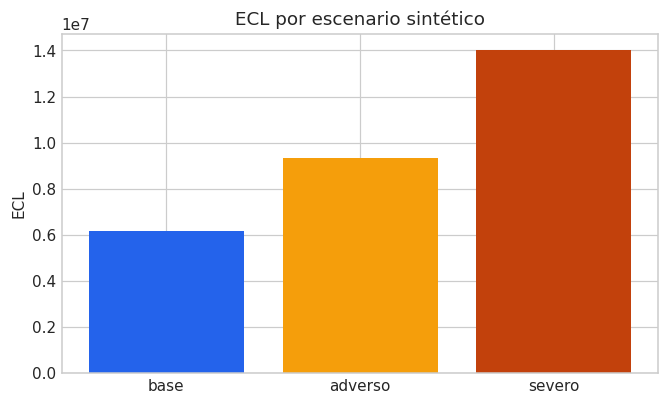

In [3]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(resumen.keys(), resumen.values(), color=['#2463eb','#f59e0b','#c2410c'])
ax.set(title='ECL por escenario sintético', ylabel='ECL')
plt.show()

In [4]:
base = escenarios['base']
base.groupby('stage').agg(cuentas=('loan_id','size'), ecl=('ecl','sum'), exposicion=('ead','sum')).round(2)

Out[0]: 
       cuentas         ecl   exposicion
stage                                  
1         1813  3526661.29  99767915.27
2          130   851250.90   6874111.81
3           57  1761924.92   3498881.40


## Backtesting de PD
Se simulan defaults OOT coherentes con la PD sólo en exposiciones no Stage 3 para ilustrar la tabla de calibración. En uso real se reemplaza por una muestra OOT gobernada.

In [5]:
rng = np.random.default_rng(12)
performing = cartera.loc[escenarios["base"].stage.ne(3)]
default_oot = rng.binomial(1, performing.pd_12m)
calibracion = backtest_pd(performing.pd_12m, default_oot)
calibracion

Out[0]: 
       cuentas  pd_media  default_observado  error_calibracion
banda                                                         
0          195  0.011426           0.010256          -0.001170
1          194  0.021462           0.000000          -0.021462
2          194  0.030372           0.036082           0.005710
3          194  0.038869           0.046392           0.007522
4          195  0.048829           0.071795           0.022965
5          194  0.062519           0.061856          -0.000663
6          194  0.080652           0.092784           0.012131
7          194  0.103465           0.128866           0.025401
8          194  0.139374           0.170103           0.030729
9          195  0.245659           0.210256          -0.035402


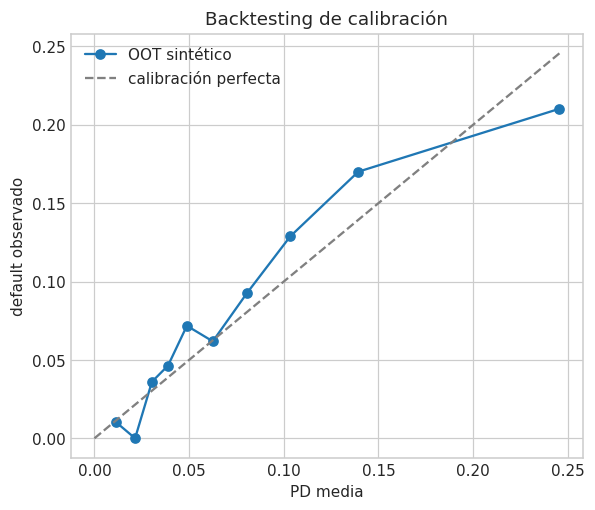

In [6]:
fig, ax = plt.subplots(figsize=(6,5))
ax.plot(calibracion.pd_media, calibracion.default_observado, 'o-', label='OOT sintético')
ax.plot([0, max(calibracion.pd_media.max(), calibracion.default_observado.max())], [0, max(calibracion.pd_media.max(), calibracion.default_observado.max())], '--', color='gray', label='calibración perfecta')
ax.set(xlabel='PD media', ylabel='default observado', title='Backtesting de calibración')
ax.legend(); plt.show()

## Límites
No incorpora definición regulatoria de default, datos observados, overlays de gestión, recuperación histórica, ni aprobación contable. Antes de uso productivo se requiere validación independiente, gobierno de modelos y fuentes trazables.

## Desarrollo semanal: mecanismo, sensibilidad y controles

Las celdas nuevas recalculan experimentos específicos. Las salidas históricas anteriores se conservan como evidencia separada y no sustituyen esta ejecución.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
SEED=20261018


### PD condicional, marginal y acumulada
Con hazard anual h_t, supervivencia S_t=exp(−Σh_j), PD marginal m_t=S_{t−1}(1−exp(−h_t)) y acumulada 1−S_t. Sumar probabilidades condicionales de default no equivale a una probabilidad lifetime y puede superar uno. El primer control reconcilia la masa de default con supervivencia.

El motor conserva EAD constante para las aproximaciones de Stage 1/2. Stage 3 ahora usa flujos de recuperación esperados y saldo bruto financiado explícitos; exige esos inputs y no multiplica su pérdida por una PD futura. Las hipótesis de recuperación siguen siendo sintéticas. La cifra no se presenta como una provisión contable aprobada.

In [8]:
from src.ifrs9_engine import pd_lifetime,stage
import pandas as pd
annual=np.array([.01,.05,.2,.5])
conditional,marginal=pd_lifetime(pd.Series(annual),horizonte=8,crecimiento_hazard=.1)
hazard=-np.log1p(-annual[:,None])*1.1**np.arange(8)
survival=np.exp(-np.cumsum(hazard,axis=1))
assert np.allclose(np.cumsum(marginal,axis=1),1-survival)
assert np.all(marginal>=0) and np.all(marginal.sum(axis=1)<=1+1e-12)
display(pd.DataFrame({'PD anual':annual,'suma condicional incorrecta':conditional.sum(axis=1),
    'PD acumulada correcta':marginal.sum(axis=1)}))

,PD anual,suma condicional incorrecta,PD acumulada correcta
0,0.01,0.114074,0.108575
1,0.05,0.564653,0.443776
2,0.20,2.170991,0.922062
3,0.50,4.961840,0.999639


### Comparar exposición amortizante y constante
Se calcula una operación de 100 unidades, LGD 0.45 y hazard anual constante. El horizonte se usa para default hasta 12 meses o durante la vida; en un modelo completo, la pérdida asociada a default en los primeros 12 meses incluye los shortfalls posteriores pertinentes. No se confunde una curva de default con la fecha de recuperación.

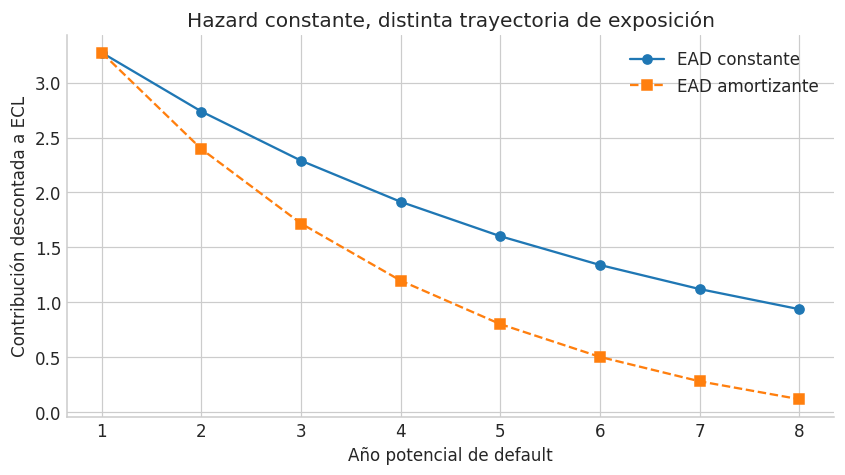

,año,PD marginal,ECL exposición constante,ECL amortizante
0,1,0.08000,3.27273,3.27273
1,2,0.07360,2.73719,2.39504
2,3,0.06771,2.28929,1.71696
3,4,0.06230,1.91468,1.19667
4,5,0.05731,1.60137,0.80068
5,6,0.05273,1.33932,0.50225
6,7,0.04851,1.12016,0.28004
7,8,0.04463,0.93686,0.11711


In [9]:
horizon=8;pd_annual=.08;lgd=.45;eir=.1
_,marginal=pd_lifetime(pd.Series([pd_annual]),horizon,crecimiento_hazard=0.)
years=np.arange(1,horizon+1);discount=(1+eir)**(-years)
ead_constant=np.full(horizon,100.);ead_amortizing=100*(horizon-years+1)/horizon
contributions=pd.DataFrame({'año':years,'PD marginal':marginal[0],
    'ECL exposición constante':marginal[0]*ead_constant*lgd*discount,
    'ECL amortizante':marginal[0]*ead_amortizing*lgd*discount})
display(contributions.round(5))
assert contributions['ECL amortizante'].sum()<=contributions['ECL exposición constante'].sum()
fig,ax=plt.subplots(figsize=(9,4.5))
ax.plot(years,contributions['ECL exposición constante'],'o-',label='EAD constante')
ax.plot(years,contributions['ECL amortizante'],'s--',label='EAD amortizante')
ax.set(xlabel='Año potencial de default',ylabel='Contribución descontada a ECL',title='Hazard constante, distinta trayectoria de exposición')
ax.legend();plt.show()

### Sensibilidad al SICR sin cambiar la cartera
Se varía únicamente el umbral relativo PD actual/origen. Las probabilidades y la mora permanecen fijas. El ejercicio cuantifica discontinuidades por staging, sin recomendar un umbral ni afirmar que la razón de PD sea un criterio suficiente de SICR.

In [10]:
staging_rows=[]
for threshold in [1.25,1.5,2.,2.5,3.]:
    stages=stage(cartera.pd_12m,cartera.pd_origen,cartera.dpd,threshold)
    base=ecl_componentes(cartera,'base')
    illustrative=np.select([stages.eq(1),stages.eq(3)],[base.ecl_12m,base.ecl],default=base.ecl_lifetime)
    staging_rows.append(dict(umbral=threshold,stage1=int(stages.eq(1).sum()),stage2=int(stages.eq(2).sum()),stage3=int(stages.eq(3).sum()),ECL_ilustrativa=illustrative.sum()))
staging_table=pd.DataFrame(staging_rows);display(staging_table.round(2))
assert (staging_table[['stage1','stage2','stage3']].sum(axis=1)==len(cartera)).all()
assert staging_table.stage3.nunique()==1
print('Stage 3 se mantiene en su base de flujos de recuperación durante este barrido de SICR; no es una calibración empírica.')

Stage 3 se mantiene en su base de flujos de recuperación durante este barrido de SICR; no es una calibración empírica.


,umbral,stage1,stage2,stage3,ECL_ilustrativa
0,1.25,496,1447,57,13085975.89
1,1.50,1195,748,57,9383232.19
2,2.00,1813,130,57,6139837.11
3,2.50,1813,130,57,6139837.11
4,3.00,1813,130,57,6139837.11


### Límites del desarrollo
La simulación distingue errores de agregación, amortización y sensibilidad de staging. No valida parámetros de una entidad ni sustituye interpretación normativa, política contable o validación independiente. Escenarios macro, recuperaciones, curas y fecha de información requieren un diseño separado y fuentes gobernadas.

## Revisión de riesgo: Stage 3 con recuperaciones explícitas
El proxy anterior aplicaba una PD futura a exposiciones ya deterioradas. El motor separa ahora el saldo bruto financiado y los flujos netos esperados de recuperación. En el alcance no-POCI de este laboratorio, se calcula saldo bruto menos valor presente de recuperaciones, se expone cualquier excedente y se aplica un piso de cero a la cifra ilustrativa de allowance.

Los horizontes de default `ecl_12m` y `ecl_lifetime` no aplican a estas filas y se dejan como NaN, con `ecl_basis=funded_recovery_cashflows`. El piso y los shocks sobre recuperaciones son decisiones explícitas del prototipo, no una política contable certificada.

In [11]:
from src.ifrs9_engine import credit_impaired_shortfall
impaired=cartera.iloc[[0]].copy();impaired['ead']=100.;impaired['gross_carrying_amount']=100.;impaired['dpd']=95
impaired['recovery_cashflows']=[(60.,)];impaired['recovery_times']=[(2.,)]
stage3_rows=[]
for pd_future in [.001,.01,.1,.5,1.]:
    impaired['pd_12m']=pd_future
    measured=ecl_componentes(impaired,tasa_descuento=.1)
    stage3_rows.append(dict(PD_future=pd_future,ECL=measured.ecl.iloc[0],basis=measured.ecl_basis.iloc[0]))
stage3_table=pd.DataFrame(stage3_rows);display(stage3_table)
assert stage3_table.ECL.nunique()==1
assert np.isclose(stage3_table.ECL.iloc[0],100-60/1.1**2)
assert measured.ecl_12m.isna().all() and measured.ecl_lifetime.isna().all()


,PD_future,ECL,basis
0,0.001,50.413223,funded_recovery_cashflows
1,0.010,50.413223,funded_recovery_cashflows
2,0.100,50.413223,funded_recovery_cashflows
3,0.500,50.413223,funded_recovery_cashflows
4,1.000,50.413223,funded_recovery_cashflows


### Monto y tiempo de recuperación
Se varía monto total esperado y año de recuperación para el mismo saldo bruto de 100. A tasa positiva, recuperar el mismo monto más tarde aumenta el shortfall descontado. Este efecto existe aunque la PD futura no cambie.

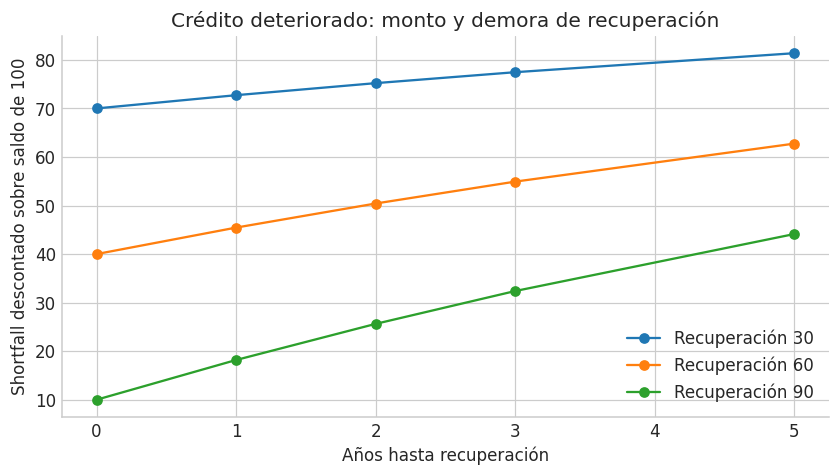

,amount,year,pv_expected_recoveries,raw_shortfall,ecl,recovery_surplus
0,30.0,0.0,30.00000,70.00000,70.00000,0.0
1,30.0,1.0,27.27273,72.72727,72.72727,0.0
2,30.0,2.0,24.79339,75.20661,75.20661,0.0
3,30.0,3.0,22.53944,77.46056,77.46056,0.0
4,30.0,5.0,18.62764,81.37236,81.37236,0.0
5,60.0,0.0,60.00000,40.00000,40.00000,0.0
6,60.0,1.0,54.54545,45.45455,45.45455,0.0
7,60.0,2.0,49.58678,50.41322,50.41322,0.0
8,60.0,3.0,45.07889,54.92111,54.92111,0.0
9,60.0,5.0,37.25528,62.74472,62.74472,0.0


In [12]:
recovery_rows=[]
for amount in [30.,60.,90.]:
    for year in [0.,1.,2.,3.,5.]:
        result=credit_impaired_shortfall(100.,[amount],[year],.1)
        recovery_rows.append(dict(amount=amount,year=year,**result))
recovery_table=pd.DataFrame(recovery_rows);display(recovery_table.round(5))
fig,ax=plt.subplots(figsize=(9,4.5))
for amount,group in recovery_table.groupby('amount'):
    ax.plot(group.year,group.ecl,'o-',label=f'Recuperación {amount:g}')
ax.set(xlabel='Años hasta recuperación',ylabel='Shortfall descontado sobre saldo de 100',title='Crédito deteriorado: monto y demora de recuperación')
ax.legend();plt.show()
for amount,group in recovery_table.groupby('amount'):assert np.all(np.diff(group.ecl)>=-1e-12)


### Fuentes y alcance
La revisión contrastó la definición de pérdidas crediticias y el descuento con material público de la IFRS Foundation. El texto consolidado completo requiere acceso; no se afirma haber certificado cumplimiento contable. Véase el [material público sobre activos deteriorados](https://www.ifrs.org/projects/completed-projects/2019/curing-of-a-credit-impaired-financial-asset-ifrs-9/tad-presentation-of-unrecognised-interest-following-the-curing-of-a-credit-impaired-financial-asset/), identificado como decisión tentativa histórica. La referencia no sustituye el texto vigente ni políticas de una entidad.

No se modelan POCI, cambios contractuales, curas, interés neto ni asientos. Stage 1/2 siguen siendo aproximaciones anuales de EAD/LGD constante; Stage 3 exige inputs de recuperaciones y fecha de información trazables.